<a href="https://colab.research.google.com/github/tahta-id/Project-Google-Colab/blob/main/Fire_Detection_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
pip install kagglehub opencv-python numpy pandas tensorflow scikit-learn seaborn matplotlib

--- Mengunduh Dataset Fire Detection via kagglehub ---


100%|██████████| 132M/132M [00:00<00:00, 138MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/atulyakumar98/test-dataset/versions/1
Total gambar valid: 644
Daftar Kelas Terdeteksi: ['0', '1']
Sampel citra untuk Modul 1-3: /root/.cache/kagglehub/datasets/atulyakumar98/test-dataset/versions/1/Fire-Detection/0/465.jpg



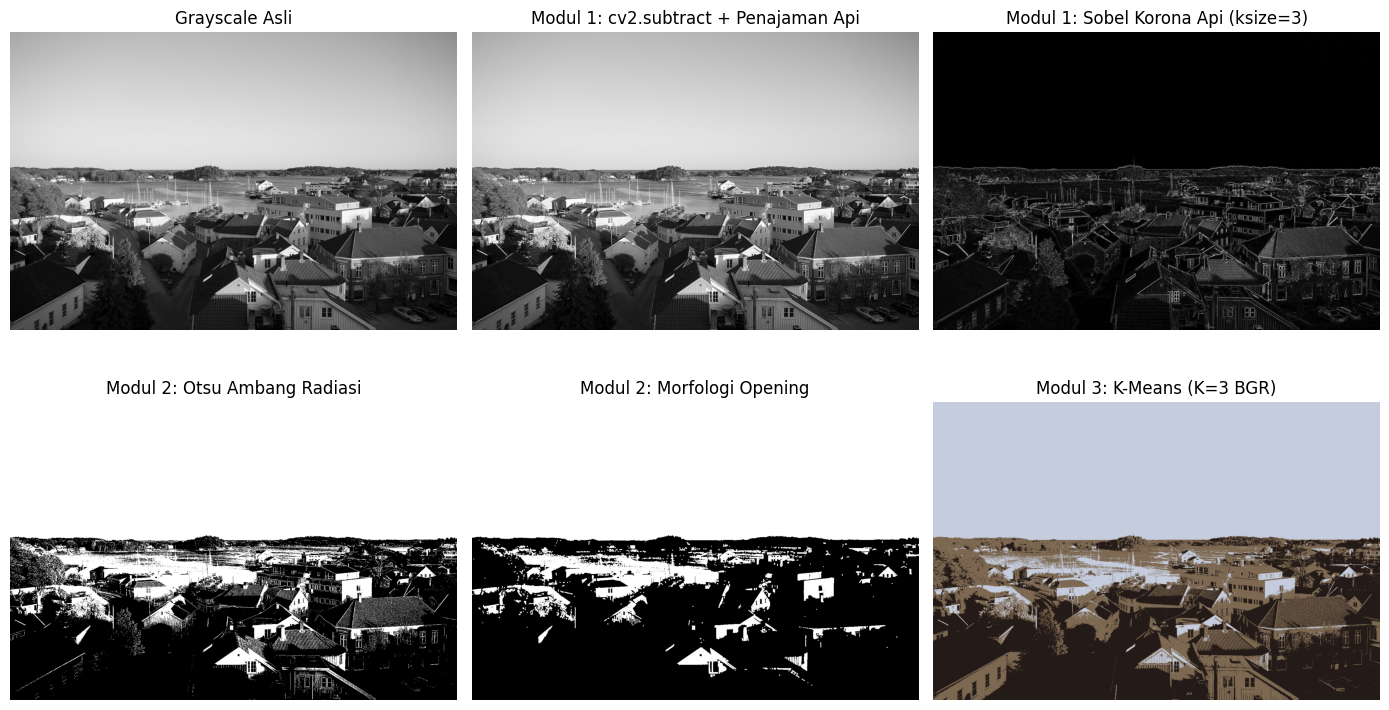


--- Modul 4: Menyiapkan Pembagian Dataset Train & Val (Batch 32) ---
Found 515 validated image filenames belonging to 2 classes.
Found 129 validated image filenames belonging to 2 classes.

--- Melatih Model Klasifikasi Deteksi Api ---
Epoch 1/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.7883 - loss: 0.6013 - val_accuracy: 0.8217 - val_loss: 0.4550
Epoch 2/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.8485 - loss: 0.3530 - val_accuracy: 0.8140 - val_loss: 0.3532
Epoch 3/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.8854 - loss: 0.2746 - val_accuracy: 0.8605 - val_loss: 0.3088
Epoch 4/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.9087 - loss: 0.2079 - val_accuracy: 0.9070 - val_loss: 0.2628
Epoch 5/5
17/17 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.9320 - loss: 0.1745 - val_accuracy: 0.9225 - val_loss: 0.2438
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 333ms/step

================ CLASSIFICATION REPORT AKHIR ================
              precision    recall  f

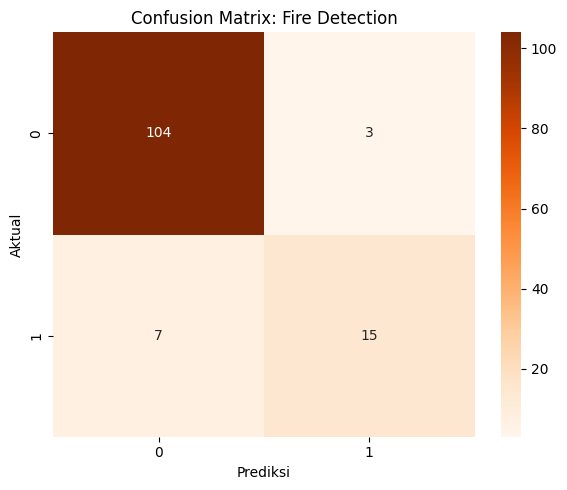

In [2]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import kagglehub

# =====================================================================
# 0. UNDUH DATASET DETEKSI API MENGGUNAKAN KAGGLEHUB
# =====================================================================
print("--- Mengunduh Dataset Fire Detection via kagglehub ---")
path = kagglehub.dataset_download("atulyakumar98/test-dataset")
print("Path to dataset files:", path)

# 1. Cari semua file gambar (.jpg / .jpeg / .png) di seluruh subfolder dataset
image_files = glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.jpeg"), recursive=True) + \
              glob.glob(os.path.join(path, "**", "*.png"), recursive=True)

if not image_files:
    raise FileNotFoundError("Tidak ditemukan file gambar di dalam dataset!")

# 2. Susun DataFrame berdasarkan nama direktori kelas (misal: 'Fire' dan 'Non_Fire' / 'No_Fire')
data = []
for img_path in image_files:
    class_name = os.path.basename(os.path.dirname(img_path))
    data.append({'file_path': img_path, 'class_str': class_name})

df = pd.DataFrame(data)

# Filter folder utama/non-kelas jika ada (ambil kelas yang jumlah sampelnya mencukupi)
class_counts = df['class_str'].value_counts()
valid_classes = class_counts[class_counts > 5].index
df = df[df['class_str'].isin(valid_classes)].reset_index(drop=True)

print(f"Total gambar valid: {len(df)}")
print(f"Daftar Kelas Terdeteksi: {df['class_str'].unique().tolist()}")

# Ambil 1 sampel citra api untuk demonstrasi Modul 1-3
fire_samples = df[df['class_str'].str.contains("fire", case=False)]
if not fire_samples.empty:
    sample_img_path = fire_samples['file_path'].iloc[0]
else:
    sample_img_path = df['file_path'].iloc[0]

print(f"Sampel citra untuk Modul 1-3: {sample_img_path}\n")


# =====================================================================
# MODUL 1: Subtraksi Asap cv2.subtract, Penajaman Api & Sobel (ksize=3)
# =====================================================================
def modul_1_processing(image_path):
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise ValueError(f"Gagal memuat citra: {image_path}")

    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # 1. Pemburaman Gauss untuk meredakan kepulan asap
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # 2. Subtraksi intensitas gambar menggunakan cv2.subtract agar asap mereda
    high_freq_detail = cv2.subtract(gray, blurred)

    # Satukan detail struktur cahaya terang dengan gambar dasar untuk menajamkan percikan api
    sharpened = cv2.addWeighted(gray, 1.0, high_freq_detail, 1.5, 0)

    # 3. Operasi Sobel (ksize=3) merunut keliling korona api menjalar
    sobel_x = cv2.Sobel(sharpened, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(sharpened, cv2.CV_64F, 0, 1, ksize=3)

    sobel_mag = cv2.magnitude(sobel_x, sobel_y)
    sobel_uint8 = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)

    return gray, sharpened, sobel_uint8


# =====================================================================
# MODUL 2: Ambang Otsu Radiasi Api & Morfologi Opening
# =====================================================================
def modul_2_processing(sharpened_img):
    # 1. Segregasi parameter histogram piksel biner otomatis (Otsu)
    # Memotong batas radiasi pendar titik api terpanas di pusat terhadap latar
    _, otsu_thresh = cv2.threshold(sharpened_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # 2. Opening biner untuk memusnahkan kesalahan baca pantulan logam/infrastruktur
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    clean_mask = cv2.morphologyEx(otsu_thresh, cv2.MORPH_OPEN, kernel, iterations=1)

    return otsu_thresh, clean_mask


# =====================================================================
# MODUL 3: K-Means BGR Color Segmentation (K=3)
# =====================================================================
def modul_3_processing(image_path):
    img_bgr = cv2.imread(image_path)

    # 1. Manipulasi baris koordinat rentang array gambar 3 channel BGR
    pixel_values = img_bgr.reshape((-1, 3))
    pixel_values = np.float32(pixel_values)

    # 2. K-Means dengan K=3 klaster untuk menghimpun:
    # - Nyala inti suhu tinggi (keputihan terang)
    # - Area pancaran suhu sedang (oranye)
    # - Kabut kepulan asap/latar hutan gelap murni
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    k = 3

    _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    centers = np.uint8(centers)
    segmented_data = centers[labels.flatten()]
    segmented_image = segmented_data.reshape(img_bgr.shape)

    # Konversi BGR ke RGB untuk tampilan visualisasi
    segmented_rgb = cv2.cvtColor(segmented_image, cv2.COLOR_BGR2RGB)

    return segmented_rgb


# =====================================================================
# MODUL 4: CNN Dropout, Batch Size 32 & Classification Report
# =====================================================================
def modul_4_train_and_eval(df, img_size=(128, 128), batch_size=32, epochs=5):
    print("\n--- Modul 4: Menyiapkan Pembagian Dataset Train & Val (Batch 32) ---")

    # Split Stratified (80% Train, 20% Val)
    train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['class_str'])

    datagen = ImageDataGenerator(rescale=1./255)

    train_gen = datagen.flow_from_dataframe(
        dataframe=train_df,
        x_col='file_path',
        y_col='class_str',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=True
    )

    val_gen = datagen.flow_from_dataframe(
        dataframe=val_df,
        x_col='file_path',
        y_col='class_str',
        target_size=img_size,
        batch_size=batch_size,
        class_mode='categorical',
        shuffle=False
    )

    num_classes = len(train_df['class_str'].unique())

    # Bangun Arsitektur Model CNN dengan Neuron Dropout Penahan Overfitting
    model = models.Sequential([
        layers.Input(shape=(img_size[0], img_size[1], 3)),

        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation='relu'),

        # Neuron Dropout penahan overfitting
        layers.Dropout(0.5),
        layers.Dense(num_classes, activation='softmax')
    ])

    model.compile(
        optimizer=optimizers.Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    print("\n--- Melatih Model Klasifikasi Deteksi Api ---")
    model.fit(train_gen, validation_data=val_gen, epochs=epochs)

    # Evaluasi Prediksi pada Data Validasi
    val_gen.reset()
    y_pred_probs = model.predict(val_gen)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = val_gen.classes

    labels_map = {v: k for k, v in val_gen.class_indices.items()}
    class_names = [labels_map[i] for i in range(num_classes)]

    # Cetak Tabulasi Classification Report Akhir
    print("\n================ CLASSIFICATION REPORT AKHIR ================")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

    # Confusion Matrix Visualisasi
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', xticklabels=class_names, yticklabels=class_names)
    plt.title('Confusion Matrix: Fire Detection')
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.tight_layout()
    plt.show()


# =====================================================================
# EKSEKUSI UTAMA PIPELINE
# =====================================================================
if __name__ == "__main__":
    # Eksekusi Modul 1
    gray_img, sharpened_img, sobel_uint8 = modul_1_processing(sample_img_path)

    # Eksekusi Modul 2
    otsu_thresh, clean_mask = modul_2_processing(sharpened_img)

    # Eksekusi Modul 3
    kmeans_segmented = modul_3_processing(sample_img_path)

    # Visualisasi Modul 1 - 3
    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    axes[0, 0].imshow(gray_img, cmap='gray')
    axes[0, 0].set_title('Grayscale Asli')

    axes[0, 1].imshow(sharpened_img, cmap='gray')
    axes[0, 1].set_title('Modul 1: cv2.subtract + Penajaman Api')

    axes[0, 2].imshow(sobel_uint8, cmap='gray')
    axes[0, 2].set_title('Modul 1: Sobel Korona Api (ksize=3)')

    axes[1, 0].imshow(otsu_thresh, cmap='gray')
    axes[1, 0].set_title('Modul 2: Otsu Ambang Radiasi')

    axes[1, 1].imshow(clean_mask, cmap='gray')
    axes[1, 1].set_title('Modul 2: Morfologi Opening')

    axes[1, 2].imshow(kmeans_segmented)
    axes[1, 2].set_title('Modul 3: K-Means (K=3 BGR)')

    for ax in axes.ravel():
        ax.axis('off')
    plt.tight_layout()
    plt.show()

    # Eksekusi Modul 4 (Training Model & Tabulasi Classification Report)
    modul_4_train_and_eval(df, epochs=5)